In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D9/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
#df_scm = pd.read_csv(main_dir + 'scm.csv')
#df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard]#, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,98521081,0.05,0.00,100.00,0.00,2304,98518777,61522,0,cosine,[title],1024,0,1,salted_qgrams,,4
1,Matching with cosine,48404142,0.10,0.00,100.00,0.01,2304,48401838,61522,0,cosine,[title],1024,0,1,salted_qgrams,,4
2,Matching with cosine,18311998,0.15,0.01,100.00,0.03,2304,18309694,61522,0,cosine,[title],1024,0,1,salted_qgrams,,4
3,Matching with cosine,6806190,0.20,0.03,100.00,0.07,2304,6803886,61522,0,cosine,[title],1024,0,1,salted_qgrams,,4
4,Matching with cosine,2702740,0.25,0.09,100.00,0.17,2304,2700436,61522,0,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1820,Matching with jaccard,3962942,0.75,0.06,97.01,0.11,2235,3960707,61453,69,jaccard,[title],1024,0,32,salted_qgrams,,4
1821,Matching with jaccard,591908,0.80,0.37,94.79,0.74,2184,589724,61402,120,jaccard,[title],1024,0,32,salted_qgrams,,4
1822,Matching with jaccard,29701,0.85,7.07,91.15,13.12,2100,27601,61318,204,jaccard,[title],1024,0,32,salted_qgrams,,4
1823,Matching with jaccard,2706,0.90,71.99,84.55,77.76,1948,758,61166,356,jaccard,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    1825
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    1825
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    1825
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    1825
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    1825
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     58
2     57
3     57
4     57
5     57
6     57
7     57
8     57
9     57
10    57
11    57
12    57
13    57
14    57
15    57
16    57
17    57
18    57
19    57
20    57
21    57
22    57
23    57
24    57
25    57
26    57
27    57
28    57
29    57
30    57
31    57
32    57
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
16,Matching with cosine,2857,0.85,72.35,89.71,80.10,2067,790,61285,237,cosine,[title],1024,0,1,salted_qgrams,,4
625,Matching with dice,2816,0.85,72.94,89.15,80.23,2054,762,61272,250,dice,[title],1024,0,1,salted_qgrams,,4
1231,Matching with jaccard,2790,0.75,73.26,88.72,80.25,2044,746,61262,260,jaccard,[title],1024,0,1,salted_qgrams,,4
35,Matching with cosine,2865,0.85,72.46,90.10,80.33,2076,789,61294,228,cosine,[title],1024,0,2,salted_qgrams,,4
644,Matching with dice,2825,0.85,72.92,89.41,80.33,2060,765,61278,244,dice,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1197,Matching with dice,2562,0.95,75.37,83.81,79.37,1931,631,61149,373,dice,[title],1024,0,31,salted_qgrams,,4
1804,Matching with jaccard,2596,0.90,74.81,84.29,79.27,1942,654,61160,362,jaccard,[title],1024,0,31,salted_qgrams,,4
607,Matching with cosine,2613,0.95,74.24,84.20,78.91,1940,673,61158,364,cosine,[title],1024,0,32,salted_qgrams,,4
1216,Matching with dice,2600,0.95,74.54,84.11,79.04,1938,662,61156,366,dice,[title],1024,0,32,salted_qgrams,,4


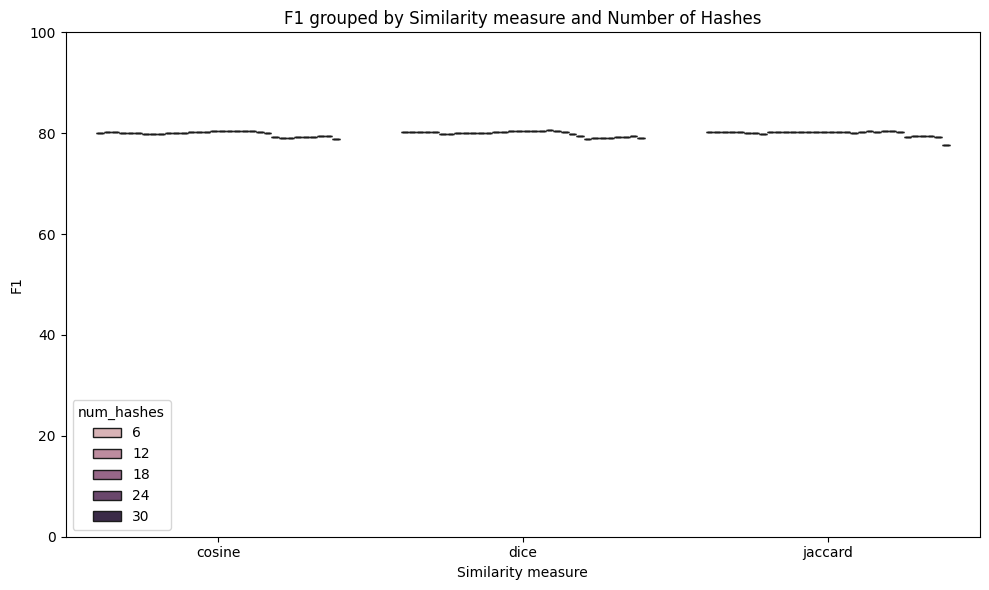

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,72.35
1,dice,1,Precision %,72.94
2,jaccard,1,Precision %,73.26
3,cosine,2,Precision %,72.46
4,dice,2,Precision %,72.92
...,...,...,...,...
283,dice,31,F1 %,79.37
284,jaccard,31,F1 %,79.27
285,cosine,32,F1 %,78.91
286,dice,32,F1 %,79.04


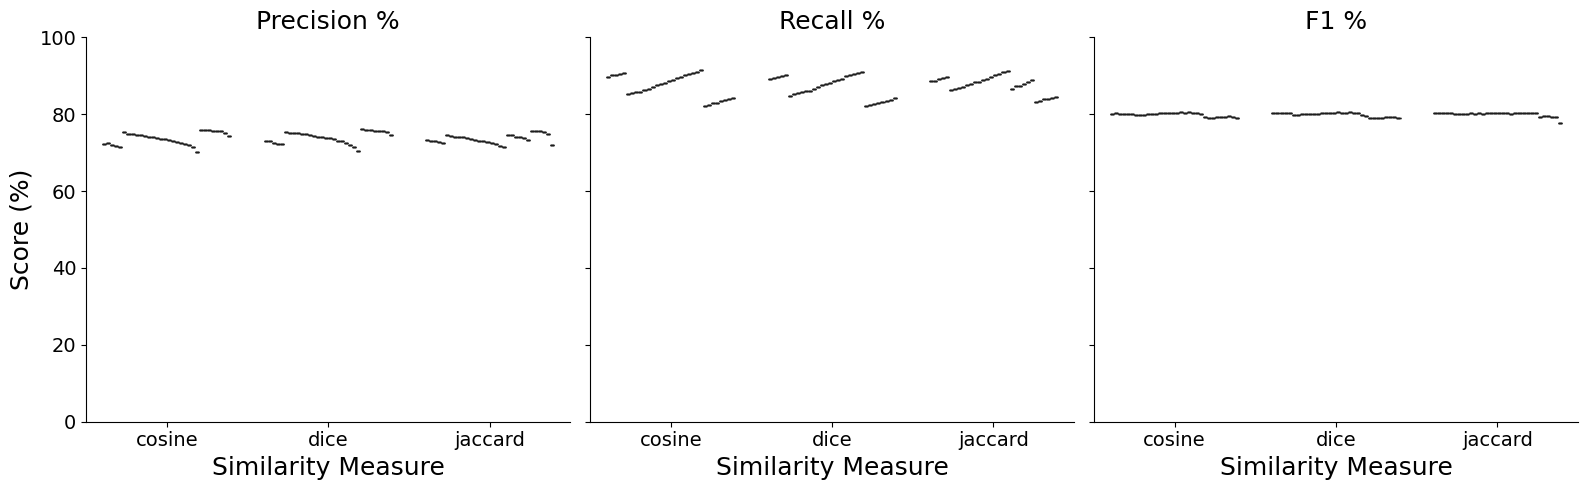

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

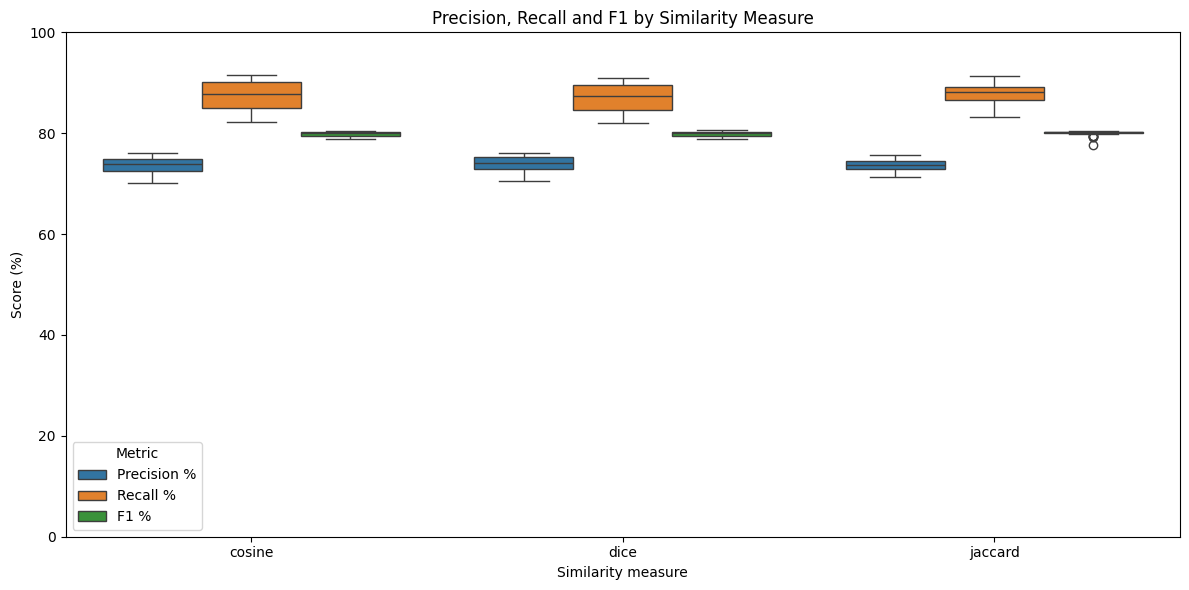

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()